# 02 · Exploratory Data Analysis & Feature Engineering (Phase 2)
**Deliverable:** exploratory analysis + the final, justified list of engineered features.

### Ground rules for this notebook
1. **Freeze the test set first.** The brief says *"do not use the test set repeatedly"*. The cleanest way to guarantee that is to split off the final test set **before** any exploration, and only explore the training portion. Otherwise, my choices about features and vocabulary would be quietly influenced by test data.
2. **Interpret cautiously.** EDA shows *associations in this dataset*, not causes. The brief's warning applies: no word is inherently fraudulent (e.g. "M-Pesa" or a transaction ID occurs in legitimate messages too).

## 0. Create and freeze the held-out test split
**Decisions**
| Choice | Decision | Why |
|---|---|---|
| Split ratio | 80% train-development / 20% held-out test | With only 643 messages, 20% (~128) gives a test set big enough for a rough estimate while leaving ~515 for training and cross-validation. A smaller test set would be too noisy; a larger one would starve training. |
| Stratified | Yes, on `label` | Keeps the ~58/42 class ratio in both parts. |
| **Grouped** | Yes, by near-duplicate group (notebook 01) | A template family can never straddle train and test -> no template leakage. |
| Mechanism | `StratifiedGroupKFold(5)` -> take fold 1 as test | scikit-learn's one-line way to get a *stratified + grouped* 80/20 split. |
| Seed | 42 (fixed) | Reproducibility. |

The test rows are written to `data/split.csv` and **not touched again until the final evaluation in notebook 04**. Model selection and threshold choice use only the training part (cross-validation inside it).

In [1]:
import sys; sys.path.insert(0, '..')   # makes src/ importable when the notebook runs from notebooks/
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, re
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from src.preprocessing import *
sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns',None,'display.width',250,'display.max_colwidth',120)
d = pd.read_csv('../data/cleaned_messages.csv')
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tr_idx, te_idx = next(sgkf.split(d, d.y, d.group))
d['split'] = 'train'; d.loc[te_idx,'split'] = 'test'
d.to_csv('../data/split.csv', index=False)
print(d.split.value_counts().to_dict())
print(pd.crosstab(d.split, d.label, normalize='index').round(3))
print('Groups shared between train and test:', len(set(d.group[d.split=='train']) & set(d.group[d.split=='test'])))

{'train': 515, 'test': 128}
label  legit   scam
split              
test   0.414  0.586
train  0.416  0.584
Groups shared between train and test: 0

**Check:** class ratio is preserved (~58% scam in both parts) and **zero** near-duplicate groups are shared between train and test, so the split is leakage-controlled.

From here on, **only the training rows are used** in this notebook.

In [2]:
tr = d[d.split=='train'].copy().reset_index(drop=True)
print(len(tr), 'training messages for EDA')

515 training messages for EDA

## 1. Class balance and risk tiers (`prelabel`)

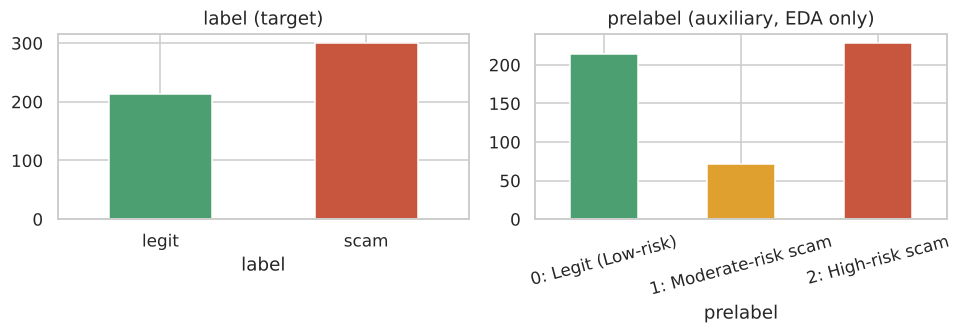

prelabel
0: Legit (Low-risk)      214
1: Moderate-risk scam     72
2: High-risk scam        229
Name: count, dtype: int64

In [3]:
fig,ax=plt.subplots(1,2,figsize=(9,3.2))
tr.label.value_counts().reindex(['legit','scam']).plot.bar(ax=ax[0],color=['#4c9f70','#c8553d'],rot=0); ax[0].set_title('label (target)')
tr.prelabel.value_counts().sort_index().plot.bar(ax=ax[1],color=['#4c9f70','#e0a030','#c8553d'],rot=15); ax[1].set_title('prelabel (auxiliary, EDA only)')
plt.tight_layout(); plt.show()
tr.prelabel.value_counts().sort_index()

**Reading:** within scams, 'high-risk' outnumber 'moderate-risk' by about 3:1. Reminder (notebook 01): `prelabel` is a refinement of `label`, so it is used here only to *describe* how scam severity relates to message features - never as a model input.

## 2. Message length
**Hypothesis:** scams tend to be longer (they must persuade, include links and instructions).

       n_chars  n_words
label                  
legit     72.5     11.5
scam     152.0     20.0
AUC of log-length alone: 0.684

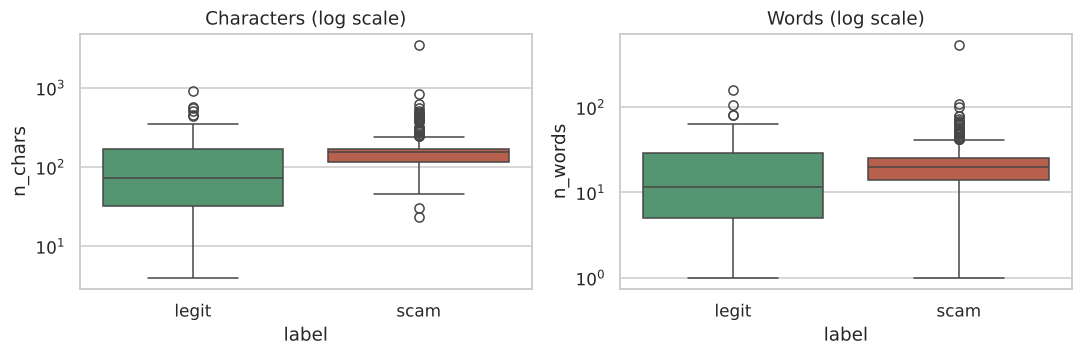

In [4]:
tr['n_chars']=tr.message_content.str.len(); tr['n_words']=tr.message_content.str.split().str.len()
fig,ax=plt.subplots(1,2,figsize=(10,3.4))
sns.boxplot(data=tr,x='label',y='n_chars',order=['legit','scam'],ax=ax[0],palette=['#4c9f70','#c8553d'],hue='label',legend=False); ax[0].set_yscale('log'); ax[0].set_title('Characters (log scale)')
sns.boxplot(data=tr,x='label',y='n_words',order=['legit','scam'],ax=ax[1],palette=['#4c9f70','#c8553d'],hue='label',legend=False); ax[1].set_yscale('log'); ax[1].set_title('Words (log scale)')
plt.tight_layout(); plt.show()
print(tr.groupby('label')[['n_chars','n_words']].median())
print('AUC of log-length alone:', round(roc_auc_score(tr.y, np.log1p(tr.n_chars)),3))

**Finding:** scams are longer (higher median) but the distributions overlap heavily; length alone gives an AUC of only ~0.68, i.e. a weak-to-moderate signal.
**Decision:** include `log(chars)` and `log(words)` as features (log because of the 3,000-character outlier), but expect them to add only modestly.

## 3. Structural indicators
Counts of: links, phone numbers, USSD codes (`*123#`), money amounts, UPPER-CASE ratio, exclamation marks, emojis, digit ratio.
We show, per class, the **average count per message** and the one-feature **AUC** (probability a random scam scores higher than a random legit message; 0.5 = useless).

In [5]:
F = pd.DataFrame([extract_hand_features(t) for t in tr.message_content])
struct = ['n_urls','n_phones','n_ussd','n_money','upper_ratio','n_exclaim','n_emoji','n_digits_ratio','n_newlines']
summ = F[struct].groupby(tr.label).mean().T.round(3)
summ['AUC (scam higher)'] = [round(roc_auc_score(tr.y, F[c]),3) for c in struct]
summ

label,legit,scam,AUC (scam higher)
n_urls,0.005,0.485,0.722
n_phones,0.061,0.140,0.536
n_ussd,0.201,0.362,0.579
n_money,0.014,0.302,0.613
upper_ratio,0.094,0.207,0.731
n_exclaim,0.159,0.671,0.643
n_emoji,0.276,0.047,0.443
n_digits_ratio,0.041,0.071,0.723
n_newlines,0.612,2.203,0.652


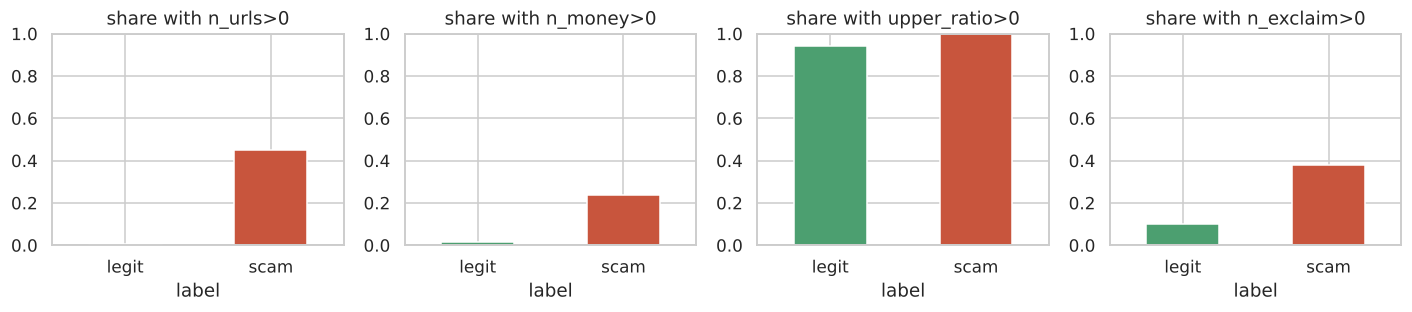

In [6]:
fig,axs=plt.subplots(1,4,figsize=(13,3))
for ax,c in zip(axs,['n_urls','n_money','upper_ratio','n_exclaim']):
    (F[c]>0).groupby(tr.label).mean().reindex(['legit','scam']).plot.bar(ax=ax,color=['#4c9f70','#c8553d'],rot=0); ax.set_title(f'share with {c}>0'); ax.set_ylim(0,1)
plt.tight_layout(); plt.show()

**Findings**
* **Links** (`n_urls`) and **money amounts** are almost exclusive to scams in this data (legit ~0%), consistent with scam goals (drive a click / quote a payout).
* **UPPER-CASE ratio** and **exclamation marks** are clearly higher in scams (shouting/urgency style).
* **Emojis** are *more* common in legit messages - because many legit messages are religious/inspirational Skiza-tune promos with praying-hands emojis. This is a **dataset-composition effect**, not a universal rule: emojis are not inherently safe, so the app must not present them as such.
* **Phone numbers and USSD codes** are weak signals (AUC ~0.54-0.58): legit promos also contain `*811*#` codes.
* **`n_newlines`** (the escaped `\n` artefact from notebook 01) is nominally discriminative (AUC ~0.65) but it is a *collection artefact*. **It is deliberately excluded from the model.**

**Decision:** keep all the non-artefact structural features. They are cheap, interpretable, and let us test (notebook 03) whether they add anything beyond the words.

## 4. Lexicon features: urgency, threats, reward, payment request, job offer, Kiswahili/Sheng, opt-out
The brief asks for these families. Two cautions from the brief shape the implementation:
* *"Do not assume that any one word is inherently fraudulent."* -> lexicons are used as **counts of a family of cues**, never as hard rules, and the model learns how much each family matters.
* *"Selected Kenyan English, Kiswahili or Sheng expressions, but only where they actually occur in the data."* -> below I **count every term in the training data** and report which never occur.

To avoid tuning the vocabulary to the labels, the lexicons were written *from domain knowledge before looking at class statistics* and kept deliberately short.

In [7]:
low = tr.message_content.map(model_text)
rows=[]
for fam, phrases in LEXICONS.items():
    for p in phrases:
        m = low.str.contains(r'(?<!\w)'+re.escape(p)+r'(?!\w)', regex=True)
        rows.append(dict(family=fam, term=p, n_msgs=int(m.sum()), scam_share=round(tr.y[m].mean(),2) if m.sum() else np.nan))
lex = pd.DataFrame(rows)
never = lex[lex.n_msgs==0]
print('Terms with ZERO occurrences in training data:', len(never), 'of', len(lex))
print(never.groupby('family').term.apply(list).to_string())

Terms with ZERO occurrences in training data: 19 of 95
family
job_offer                                                                                                     [recruit]
kiswahili_sheng                                                                                                 [ndugu]
payment_request                                                                              [transfer, processing fee]
reply_stop                                                                                                    [opt out]
threat             [suspended, blocked, deactivated, deactivate, terminated, restricted, legal action, arrest, penalty]
urgency                                                         [urgently, expired, last chance, final notice, quickly]

**Decision on non-occurring terms:** they are harmless (they contribute a count of 0 in training and would only fire on unseen messages), but listing them honours the brief's "only where they occur" rule. The Kiswahili/Sheng family is therefore limited, in effect, to the ~20 terms that *do* occur. I did **not** add Sheng slang from outside the data (e.g. "mnoma") because I cannot verify its frequency here and invented lexicon entries would be unjustified.

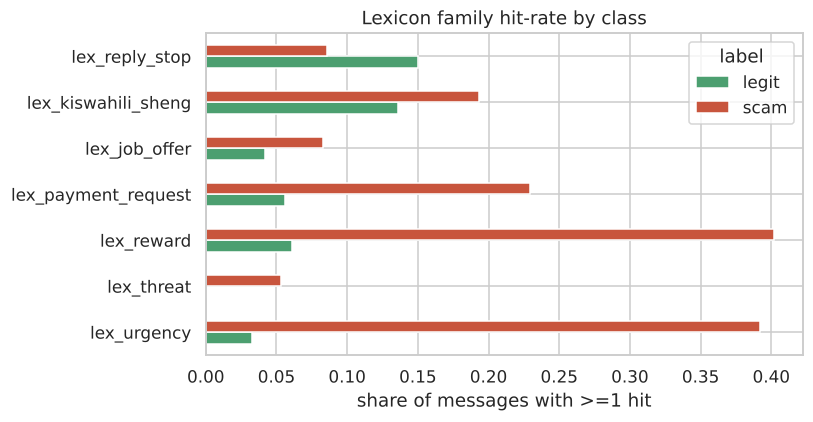

label,legit,scam,AUC
lex_urgency,0.033,0.392,0.680
lex_threat,0.000,0.053,0.527
lex_reward,0.061,0.402,0.675
lex_payment_request,0.056,0.229,0.588
lex_job_offer,0.042,0.083,0.521
lex_kiswahili_sheng,0.136,0.193,0.524
lex_reply_stop,0.150,0.086,0.468


In [8]:
FL = pd.DataFrame({f'lex_{k}':F[f'lex_{k}'] for k in LEXICONS})
tbl = (FL>0).groupby(tr.label).mean().T.round(3)
tbl['AUC'] = [round(roc_auc_score(tr.y, FL[c]),3) for c in FL]
ax = tbl[['legit','scam']].plot.barh(color=['#4c9f70','#c8553d'],figsize=(7,3.8)); ax.set_xlabel('share of messages with >=1 hit'); ax.set_title('Lexicon family hit-rate by class'); plt.show()
tbl

**Findings**
* **Urgency** (`now`, `today`, `expire`...) and **reward** (`win`, `bonus`, `free`, `cash`, `claim`...) are much more frequent in scams (hit in about 39-40% of scams vs ~3-6% of legit).
* **Payment-request** is moderately more frequent in scams; **threat/account-lock** is rare overall (only a few messages) - but when present it is scam-only. With so few hits it can't carry a model, but it's a useful *explanatory* indicator for the app.
* **Kiswahili/Sheng** is about equally common in both classes (hit in ~14% of legit vs ~19% of scam, AUC ~0.52): *using Kiswahili does not make a message a scam.* That is an important fairness-type finding - the model must not learn "Swahili = suspicious".
* **Reply-STOP / opt-out language** is actually *more* common in legit promos (carrier-style marketing), again a composition effect.
* **A single term is never decisive:** the `scam_share` column of the `lex` table shows that even words like `win` or `bonus` are not 100% scam.

In [9]:
lex[lex.n_msgs>=10].sort_values('scam_share',ascending=False).head(12)

,family,term,n_msgs,scam_share
18,threat,locked,10,1.00
32,reward,win,25,1.00
54,payment_request,paybill,13,1.00
49,payment_request,deposit,19,1.00
45,reward,daily,10,1.00
92,reply_stop,unsubscribe,13,1.00
3,urgency,now,68,0.99
29,reward,congratulations,23,0.96
47,payment_request,pay,21,0.95
35,reward,bonus,34,0.94


## 5. Most discriminative words and phrases (cautiously)
We rank words by **smoothed log-odds ratio** (scam vs legit) with a minimum document frequency of 5, so a word seen 2 times cannot top the list. We do this for unigrams and bigrams, on training data only.

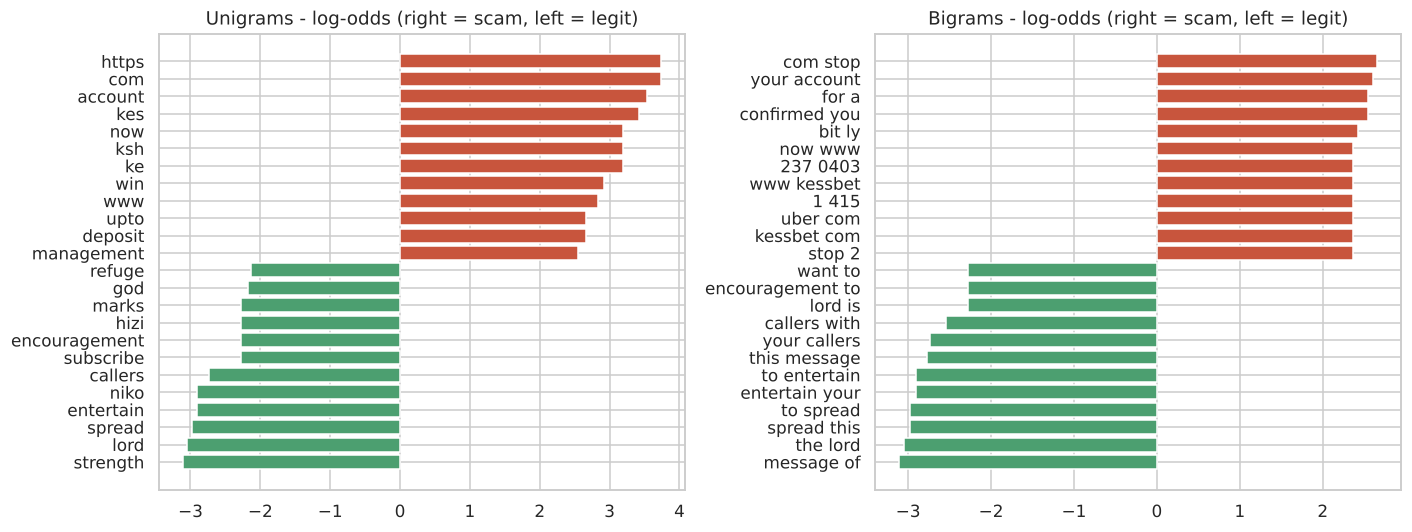

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
def logodds(ngram, min_df=5, k=12):
    cv = CountVectorizer(preprocessor=model_text, ngram_range=ngram, min_df=min_df, binary=True, token_pattern=r"(?u)\b\w+\b")
    X = cv.fit_transform(tr.message_content); names = np.array(cv.get_feature_names_out())
    s = np.asarray(X[tr.y.values==1].sum(0)).ravel()+1; l = np.asarray(X[tr.y.values==0].sum(0)).ravel()+1
    lo = np.log(s/(tr.y.sum()+2)) - np.log(l/((1-tr.y).sum()+2))
    o = np.argsort(lo)
    return pd.DataFrame({'term':names, 'log_odds':lo.round(2), 'scam_docs':s-1, 'legit_docs':l-1}).iloc[np.r_[o[::-1][:k], o[:k]]]
uni = logodds((1,1)); bi = logodds((2,2))
fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,t,title in zip(axs,[uni,bi],['Unigrams','Bigrams']):
    t=t.sort_values('log_odds'); ax.barh(t.term,t.log_odds,color=np.where(t.log_odds>0,'#c8553d','#4c9f70')); ax.set_title(title+' - log-odds (right = scam, left = legit)')
plt.tight_layout(); plt.show()

In [11]:
uni.head(12)

,term,log_odds,scam_docs,legit_docs
106,com,3.74,58,0
186,https,3.74,58,0
50,account,3.53,47,0
212,kes,3.42,42,0
210,ke,3.19,33,0
217,ksh,3.19,33,0
284,now,3.19,67,1
436,win,2.92,25,0
443,www,2.84,23,0
125,deposit,2.66,19,0


**Reading (with caution):**
* *Scam-side* terms are about **links, accounts, money and urgency** (`https`, `com`, `account`, `kes`, `ksh`, `now`, `win`, `deposit`...). These agree with the structural findings, which is reassuring.
* *Legit-side* terms are dominated by **Skiza-tune / inspirational-message vocabulary** (`strength`, `lord`, `spread this message`, `entertain your callers`, `to subscribe`, `encouragement`). These are *what legitimate messages in this dataset look like*, not universal safe words; a scammer could trivially imitate them. This is a real **limitation / domain-shift risk**: the 'legit' class is partly a specific message family.
* Words shown are *associations*, not proof of fraud.

## 6. Sensitive words that appear in both classes
The brief explicitly warns that mentioning M-Pesa or a transaction ID can occur in legitimate messages too. Let us check, instead of assuming.

In [12]:
kw = {'m-pesa / mpesa':r'm-?pesa','confirmed':r'confirmed','transaction':r'transaction','paybill / till':r'paybill|till\b','balance':r'balance'}
rows=[]
for name,pat in kw.items():
    m = low.str.contains(pat, regex=True)
    rows.append(dict(keyword=name, n_msgs=int(m.sum()), n_scam=int(tr.y[m].sum()), n_legit=int((1-tr.y)[m].sum()), scam_share=round(tr.y[m].mean(),2) if m.sum() else np.nan))
pd.DataFrame(rows)

,keyword,n_msgs,n_scam,n_legit,scam_share
0,m-pesa / mpesa,43,34,9,0.79
1,confirmed,22,20,2,0.91
2,transaction,7,7,0,1.00
3,paybill / till,22,21,1,0.95
4,balance,26,25,1,0.96


**Finding:** M-Pesa-style wording (`confirmed`, `balance`, `transaction`) is **mostly in scams in this dataset** - these are *fake* M-Pesa confirmation messages. But the legit class is not empty for them, and (crucially) a *genuine* M-Pesa receipt looks nearly the same as a fake one. **A model trained on this data would likely flag genuine M-Pesa receipts as suspicious** because genuine receipts are rare in the 'legit' class. We note this in the limitations and test it in the app's "limitations" panel.

## 7. Do the moderate-risk and high-risk scams differ?
(Preview for the optional three-class extension.)

In [13]:
FF = F[['n_chars_log','n_urls','n_money','upper_ratio','n_exclaim','lex_urgency','lex_reward','lex_payment_request']].copy()
FF['prelabel']=tr.prelabel.values
FF.groupby('prelabel').mean().round(2)

,n_chars_log,n_urls,n_money,upper_ratio,n_exclaim,lex_urgency,lex_reward,lex_payment_request
prelabel,,,,,,,,
0: Legit (Low-risk),4.27,0.00,0.01,0.09,0.16,0.03,0.07,0.06
1: Moderate-risk scam,4.26,0.03,0.03,0.08,0.28,0.11,0.49,0.06
2: High-risk scam,5.18,0.63,0.39,0.25,0.79,0.52,0.65,0.43


**Finding:** **high-risk** scams are longer and use far more links, money amounts, upper-case, urgency and payment requests; **moderate-risk** scams look structurally almost like legit messages (same length, almost no links or money) and differ mainly in *reward language* (49% vs 7%). So the high-risk tier is structurally distinct, while the moderate tier is a subtle, text-only category - expect it to be hard to separate from legit. Whether a classifier can reproduce them is tested in notebook 05.

## 8. Redundancy between engineered features

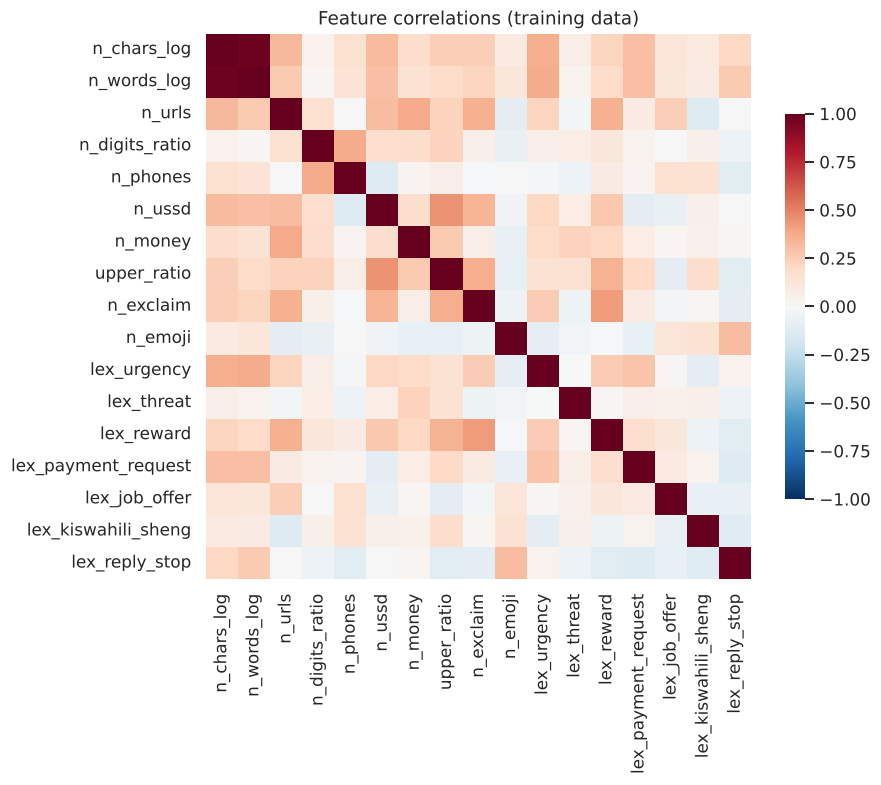

[('n_chars_log', 'n_words_log', np.float64(0.98))]

In [14]:
cols = ['n_chars_log','n_words_log','n_urls','n_digits_ratio','n_phones','n_ussd','n_money','upper_ratio','n_exclaim','n_emoji']+[f'lex_{k}' for k in LEXICONS]
cm = F[cols].corr()
plt.figure(figsize=(8,6.5)); sns.heatmap(cm,cmap='RdBu_r',center=0,vmin=-1,vmax=1,square=True,cbar_kws={'shrink':.7}); plt.title('Feature correlations (training data)'); plt.show()
hi = [(a,b,round(cm.loc[a,b],2)) for i,a in enumerate(cols) for b in cols[i+1:] if abs(cm.loc[a,b])>0.7]; hi

**Finding:** `n_chars_log` and `n_words_log` are strongly correlated (>0.9) - they carry nearly the same information. 
**Decision:** keep both anyway. Linear models with L2 regularisation (LR, SVM) handle correlated inputs gracefully, and the correlation does not harm Naive Bayes enough to matter at this scale. Removing one would be an arbitrary choice with no measurable benefit; if it matters, the ablation in notebook 03 will show it.

## 9. Final feature plan (what notebook 03 will test)
| Feature set | Content | Why |
|---|---|---|
| **A. TF-IDF unigrams** | Individual words | Brief: baseline text representation |
| **B. TF-IDF unigrams + bigrams** | Words + 2-word phrases | Brief: compare uni vs uni+bi; bigrams capture phrases such as "click here", "claim your" |
| **C. B + handcrafted** | Adds 17 structural + lexicon features (scaled) | Brief: "then investigate additional features" |

TF-IDF details and why: `sublinear_tf` (dampens very repeated words), L2 normalisation (so long messages don't dominate), `min_df=2` (drops words seen in only one message - they can't generalise and mostly are typos/IDs). TF-IDF is **inside the Pipeline**, so vocabulary and IDF weights are learned from training folds only.

**Excluded on purpose:** `prelabel` (leakage), escaped-newline count (artefact), stemming/lemmatisation and stop-word removal (a mixed English/Kiswahili/Sheng corpus has no reliable stemmer; 'reply', 'now', 'to' are informative here), character n-grams (not requested; would reduce interpretability).